# Praktikum Pengolahan Citra Digital: Sub-CPMK 5
## Meredam Derau dengan Penyaringan Spasial

Setelah praktikum ini, mahasiswa dapat membedakan derau Gaussian dan *salt-and-pepper*, menerapkan mean, Gaussian, median, serta bilateral, lalu memilih hasil berdasarkan detail citra, MSE, dan PSNR.

**Pola kerja:** prediksi, jalankan, amati, jelaskan, lalu ubah satu parameter.

## Aturan praktikum

1. Semua filter menerima input berderau yang sama. Derau dibuat sekali dengan *seed* tetap.
2. Prediksi ditulis sebelum hasil filter ditampilkan.
3. Periksa area halus, tepi, dan tekstur sebelum membaca MSE/PSNR.
4. Mean, Gaussian, dan median memakai ukuran 5 x 5. Bilateral memakai `d=9`, `sigmaColor=75`, `sigmaSpace=75`. Catat parameter ini ketika membandingkan hasil.
5. Citra contoh tersedia melalui scikit-image; tidak perlu mengunggah gambar ke Colab.

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
print("OpenCV:", cv2.__version__)
print("NumPy :", np.__version__)

OpenCV: 4.14.0
NumPy : 2.1.3


In [17]:
# Kedua citra contoh tersedia melalui scikit-image; tidak perlu mengunggah aset.
demo_bersih = data.camera().astype(np.uint8)
latihan_bersih = cv2.resize(
    data.coins().astype(np.uint8), (512, 512), interpolation=cv2.INTER_CUBIC
)

print("Demo   :", demo_bersih.shape, demo_bersih.dtype)
print("Latihan:", latihan_bersih.shape, latihan_bersih.dtype)

Demo   : (512, 512) uint8
Latihan: (512, 512) uint8


In [18]:
def tambah_derau_gaussian(image, sigma=18, seed=2026):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, sigma, image.shape)
    return np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def tambah_salt_pepper(image, amount=0.05, seed=2027):
    rng = np.random.default_rng(seed)
    result = image.copy()
    selector = rng.random(image.shape)
    result[selector < amount / 2] = 0
    result[(selector >= amount / 2) & (selector < amount)] = 255
    return result

def tampilkan(image, title="Citra", ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

def bandingkan(images, titles, figsize=(15, 4)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    if len(images) == 1:
        axes = [axes]
    for ax, image, title in zip(axes, images, titles):
        tampilkan(image, title, ax)
    plt.tight_layout()
    plt.show()

def terapkan_empat_filter(image, ksize=5):
    return {
        "Mean": cv2.blur(image, (ksize, ksize)),
        "Gaussian": cv2.GaussianBlur(image, (ksize, ksize), sigmaX=1.2, sigmaY=1.2),
        "Median": cv2.medianBlur(image, ksize),
        "Bilateral": cv2.bilateralFilter(image, d=9, sigmaColor=75, sigmaSpace=75),
    }

def tampilkan_roi(images, titles, roi, figsize=(13, 4)):
    y1, y2, x1, x2 = roi
    crops = [image[y1:y2, x1:x2] for image in images]
    bandingkan(crops, titles, figsize=figsize)

def tabel_metrik(clean, noisy, filtered):
    rows = [("Input berderau", noisy)] + list(filtered.items())
    print(f"{'Hasil':16s} | {'MSE':>9s} | {'PSNR (dB)':>9s}")
    print("-" * 42)
    for name, image in rows:
        mse = mean_squared_error(clean, image)
        psnr = peak_signal_noise_ratio(clean, image, data_range=255)
        print(f"{name:16s} | {mse:9.2f} | {psnr:9.2f}")

## 1. Citra bersih dan dua jenis derau

Derau Gaussian menambahkan perubahan acak kecil pada banyak piksel. *Salt-and-pepper* mengganti sebagian piksel dengan nilai ekstrem 0 atau 255.

**Prediksi:** pada jenis derau mana piksel pencilan lebih mudah dikenali?

Piksel pencilan akan lebih mudah dikenali pada derau ***salt-and-pepper***. Ini karena derau *salt-and-pepper* secara langsung mengganti piksel dengan nilai ekstrem (hitam murni atau putih murni), yang sangat kontras dengan piksel di sekitarnya dan mudah terlihat sebagai "titik" yang menyimpang. Sebaliknya, derau Gaussian menambahkan variasi kecil pada banyak piksel, membuatnya lebih sulit untuk mengidentifikasi satu piksel sebagai "pencilan" secara visual.

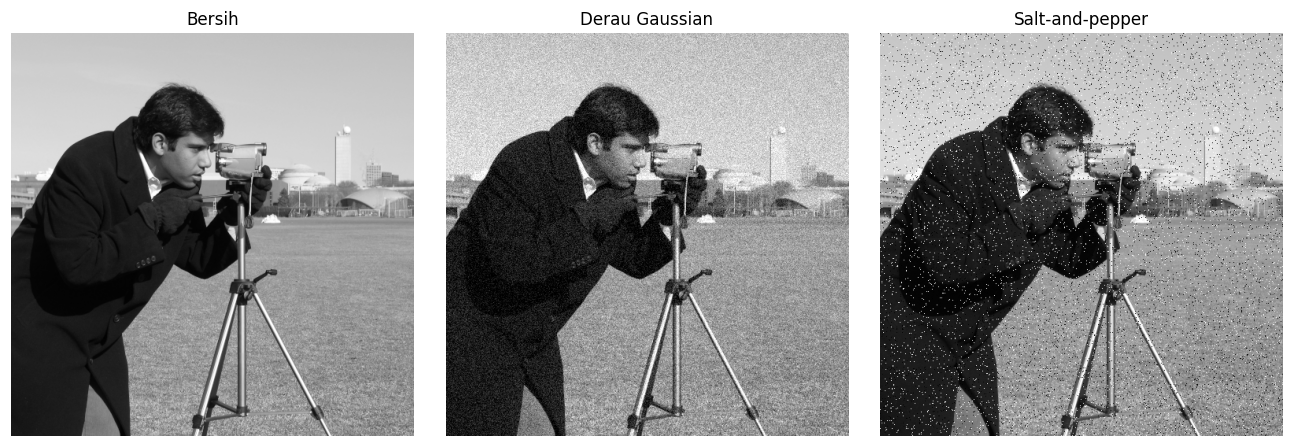

In [19]:
demo_gaussian = tambah_derau_gaussian(demo_bersih, sigma=18, seed=2026)
demo_sp = tambah_salt_pepper(demo_bersih, amount=0.05, seed=2027)

bandingkan(
    [demo_bersih, demo_gaussian, demo_sp],
    ["Bersih", "Derau Gaussian", "Salt-and-pepper"],
    figsize=(12, 4),
)

## 2. Lingkungan lokal dan satu perhitungan piksel

Perhatikan lingkungan 3 x 3 berikut. Delapan piksel bernilai 100 dan piksel pusat bernilai 255.

- *Mean*: `(8 x 100 + 255) / 9 = 117,22`
- Median: nilai tengah setelah diurutkan adalah `100`

*Mean* masih dipengaruhi nilai ekstrem. Median mengabaikan pencilan selama mayoritas tetangga masih mewakili struktur lokal.

In [20]:
lingkungan = np.array([
    [100, 100, 100],
    [100, 255, 100],
    [100, 100, 100],
], dtype=np.uint8)

print("Mean   :", lingkungan.mean())
print("Median :", np.median(lingkungan))

Mean   : 117.22222222222223
Median : 100.0


## 3. Kernel 2D dan penanganan batas

Kernel mean 3 x 3 mempunyai sembilan bobot `1/9`. Jalankan `cv2.filter2D` dan `cv2.blur` dengan mode batas yang sama, lalu bandingkan hasilnya. `filter2D` memakai korelasi tanpa membalik kernel; untuk kernel mean yang simetris, hasilnya sama dengan konvolusi.

Pada citra 2 x 2 `[[50, 80], [60, 90]]`, lingkungan piksel pojok kiri atas dengan *replicate padding* menjadi `[[50, 50, 80], [50, 50, 80], [60, 60, 90]]`. Mean-nya `570/9 = 63,33`, yang disimpan sebagai `63` pada citra `uint8`.

Amati constant 0, replicate, dan reflect 101 pada potongan citra yang sama. Perbedaan terlihat di dekat tepi.

Jumlah bobot kernel: 1.0
Selisih piksel maksimum filter2D dan blur: 0
Lingkungan pojok dengan replicate:
 [[50 50 80]
 [50 50 80]
 [60 60 90]]
Mean manual: 63.33; hasil uint8 OpenCV: 63


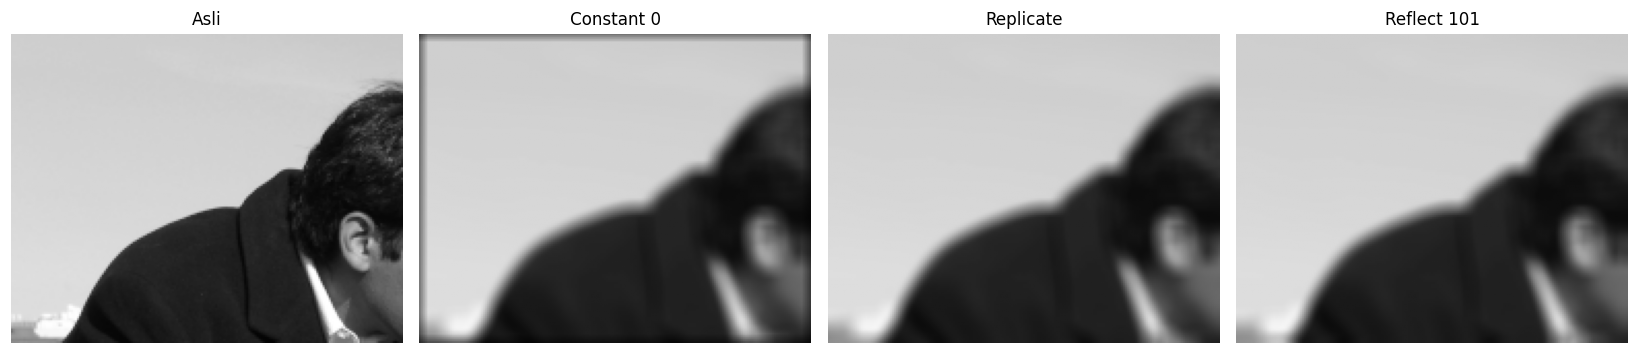

In [21]:
kernel_mean = np.ones((3, 3), dtype=np.float32) / 9
hasil_filter2d = cv2.filter2D(demo_gaussian, -1, kernel_mean,
                              borderType=cv2.BORDER_REFLECT_101)
hasil_blur = cv2.blur(demo_gaussian, (3, 3),
                     borderType=cv2.BORDER_REFLECT_101)
selisih_maksimum = np.abs(
    hasil_filter2d.astype(np.int16) - hasil_blur.astype(np.int16)
).max()
print("Jumlah bobot kernel:", kernel_mean.sum())
print("Selisih piksel maksimum filter2D dan blur:", selisih_maksimum)

pojok_asli = np.array([[50, 80], [60, 90]], dtype=np.uint8)
lingkungan_pojok = np.pad(pojok_asli, 1, mode="edge")[:3, :3]
hasil_manual = lingkungan_pojok.mean()
hasil_opencv = cv2.filter2D(pojok_asli, -1, kernel_mean,
                           borderType=cv2.BORDER_REPLICATE)[0, 0]
print("Lingkungan pojok dengan replicate:\n", lingkungan_pojok)
print(f"Mean manual: {hasil_manual:.2f}; hasil uint8 OpenCV: {hasil_opencv}")

potongan = demo_bersih[40:190, 20:210]
kernel_batas = np.ones((9, 9), dtype=np.float32) / 81
mode_batas = {
    "Constant 0": cv2.BORDER_CONSTANT,
    "Replicate": cv2.BORDER_REPLICATE,
    "Reflect 101": cv2.BORDER_REFLECT_101,
}
hasil_batas = {
    nama: cv2.filter2D(potongan, -1, kernel_batas, borderType=mode)
    for nama, mode in mode_batas.items()
}
bandingkan([potongan] + list(hasil_batas.values()),
           ["Asli"] + list(hasil_batas), figsize=(15, 4))

## 4. Empat filter

- `cv2.blur`: seluruh tetangga memiliki bobot sama.
- `cv2.GaussianBlur`: tetangga dekat pusat memiliki bobot lebih besar.
- `cv2.medianBlur`: nilai lingkungan diurutkan dan nilai tengah dipilih.
- `cv2.bilateralFilter`: tetangga dekat dengan intensitas serupa lebih berpengaruh; tepi dapat lebih terjaga, tetapi proses lebih lambat.

Bilateral memakai diameter 9, sementara tiga filter lain memakai ukuran 5 x 5. Perbandingan ini menguji keluaran pada parameter yang dinyatakan.

### Prediksi sebelum hasil demonstrasi

- Untuk derau **Gaussian**, saya memprediksi filter **Gaussian** akan menjadi yang paling sesuai. Alasannya, derau Gaussian merupakan derau acak yang terdistribusi secara normal, dan filter Gaussian dirancang khusus untuk menghaluskan jenis derau ini dengan pembobotan piksel di sekitarnya berdasarkan distribusi Gaussian.

- Untuk derau ***salt-and-pepper***, saya memprediksi filter **Median** akan menjadi yang paling efektif. Alasannya, derau *salt-and-pepper* terdiri dari piksel-piksel dengan nilai ekstrem (0 atau 255), dan filter median sangat baik dalam menghilangkan pencilan seperti ini karena ia mengganti nilai piksel dengan nilai tengah dari lingkungannya, yang tidak terpengaruh oleh nilai ekstrem.

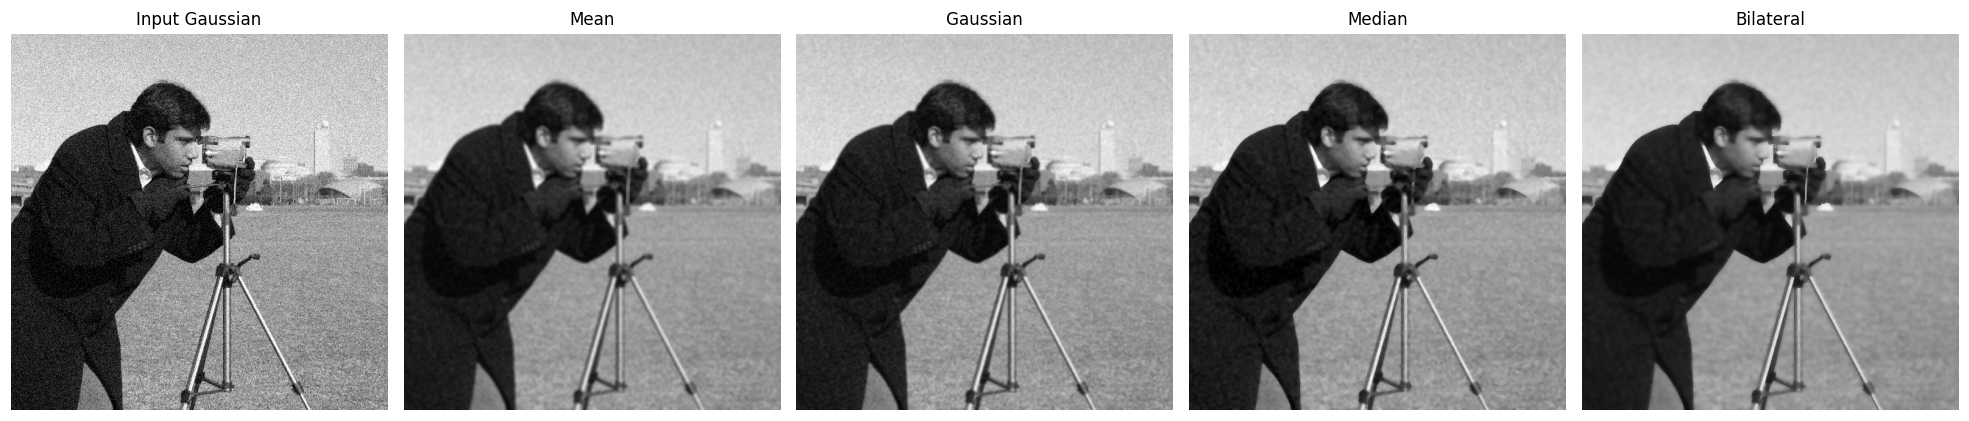

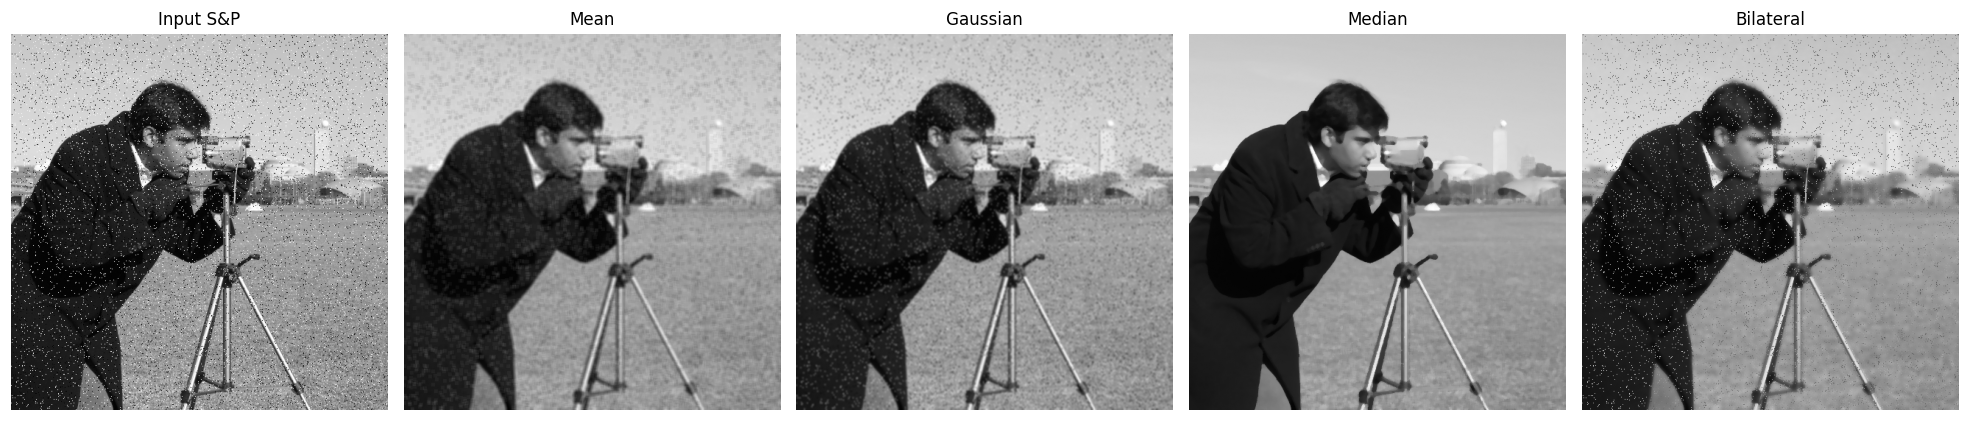

In [22]:
hasil_gaussian = terapkan_empat_filter(demo_gaussian, ksize=5)
hasil_sp = terapkan_empat_filter(demo_sp, ksize=5)

bandingkan(
    [demo_gaussian] + list(hasil_gaussian.values()),
    ["Input Gaussian"] + list(hasil_gaussian.keys()),
    figsize=(18, 4),
)

bandingkan(
    [demo_sp] + list(hasil_sp.values()),
    ["Input S&P"] + list(hasil_sp.keys()),
    figsize=(18, 4),
)

## 5. Bukti pada wilayah yang sama

Gambar utuh dapat menyembunyikan perbedaan kecil. Bandingkan area yang sama untuk melihat derau tersisa, kondisi tepi, dan tekstur.

ROI area halus


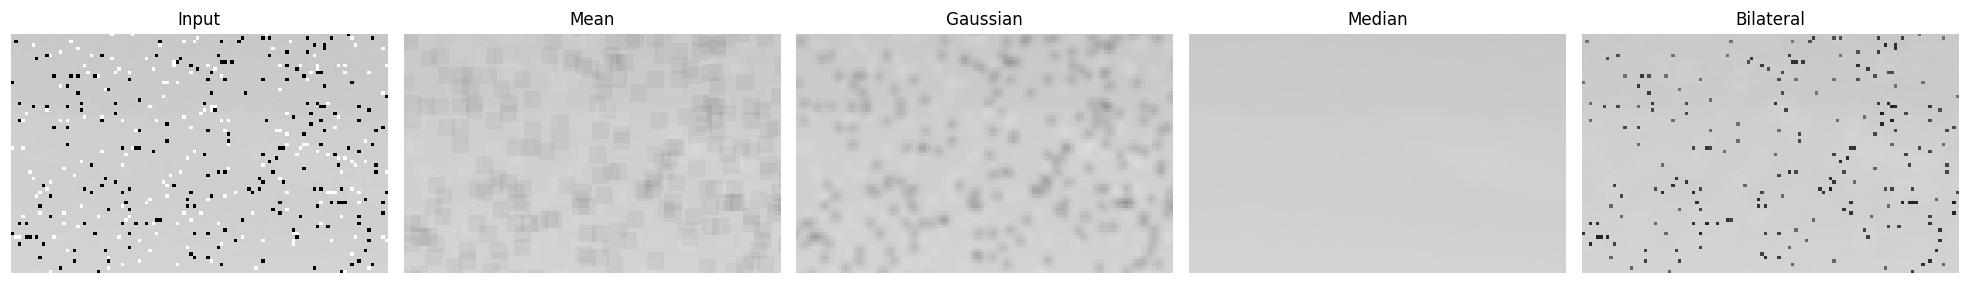

ROI tepi


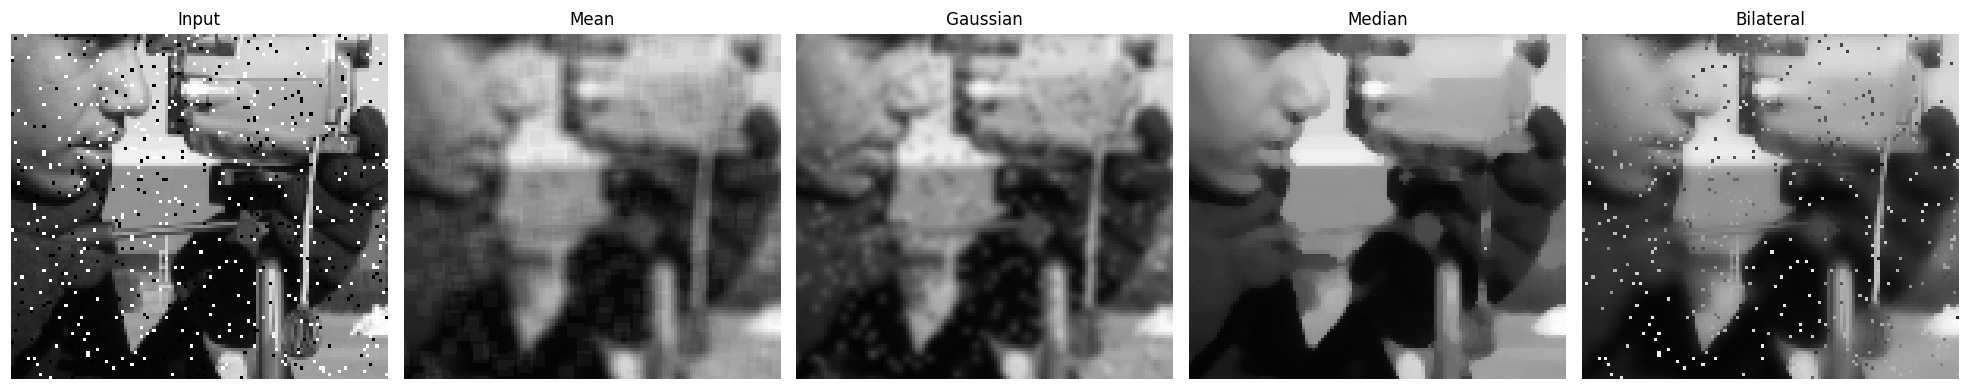

ROI tekstur


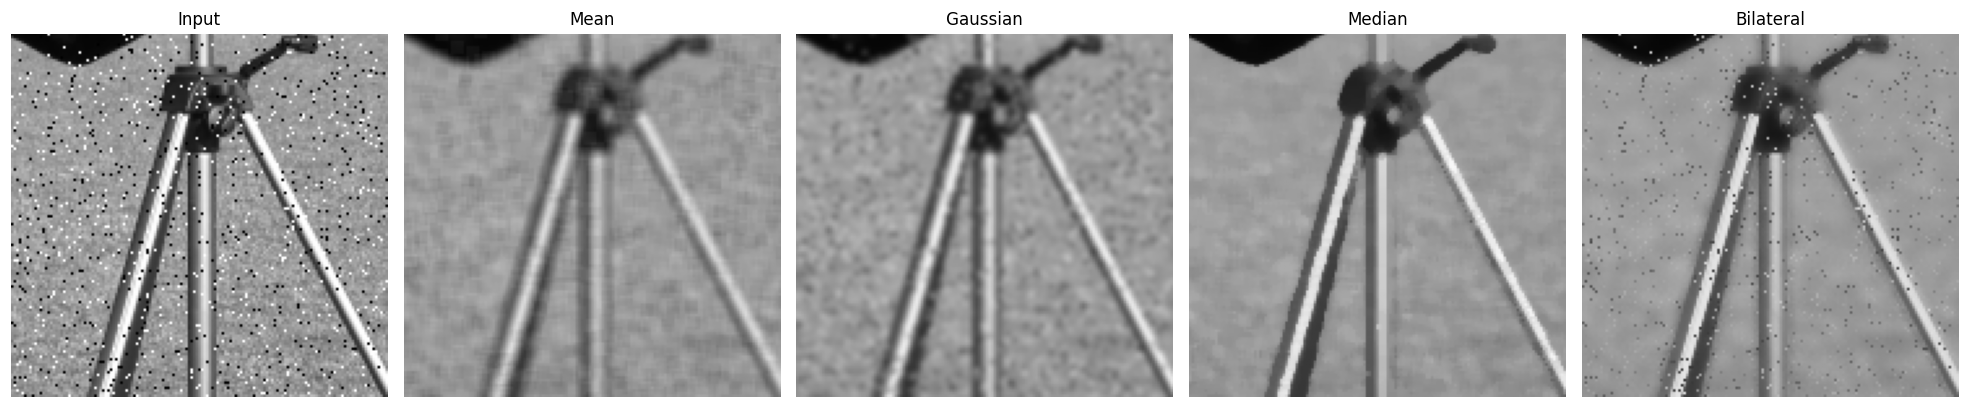

In [23]:
roi_halus = (15, 85, 15, 125)
roi_tepi = (145, 255, 210, 330)
roi_tekstur = (300, 440, 220, 365)

print("ROI area halus")
tampilkan_roi(
    [demo_sp] + list(hasil_sp.values()),
    ["Input"] + list(hasil_sp),
    roi_halus,
    figsize=(18, 4),
)

print("ROI tepi")
tampilkan_roi(
    [demo_sp] + list(hasil_sp.values()),
    ["Input"] + list(hasil_sp),
    roi_tepi,
    figsize=(18, 4),
)

print("ROI tekstur")
tampilkan_roi(
    [demo_sp] + list(hasil_sp.values()),
    ["Input"] + list(hasil_sp),
    roi_tekstur,
    figsize=(18, 4),
)

## 6. Ukuran lingkungan

Ukuran lebih besar menggunakan lebih banyak tetangga. Derau dapat berkurang, tetapi garis tipis dan tekstur juga lebih mudah hilang.

**Prediksi:** ukuran mana yang paling banyak menghilangkan derau? Ukuran mana yang berisiko menghapus detail?

Ukuran filter yang lebih besar akan paling banyak menghilangkan derau karena ia merata-ratakan atau mengambil median dari area yang lebih luas, sehingga 'melenyapkan' lebih banyak piksel derau. Namun, ukuran yang lebih besar juga berisiko tinggi menghapus detail karena proses penghalusan yang agresif dapat mengaburkan garis tipis dan tekstur asli gambar.

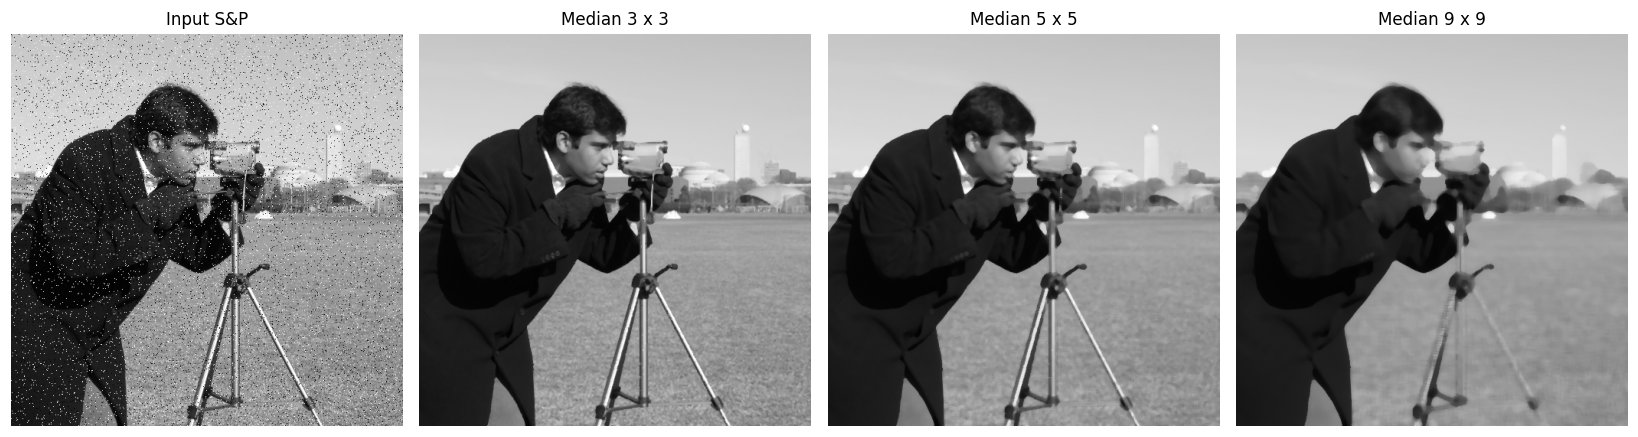

In [24]:
ukuran_dicoba = [3, 5, 9]
hasil_ukuran = [cv2.medianBlur(demo_sp, k) for k in ukuran_dicoba]
bandingkan(
    [demo_sp] + hasil_ukuran,
    ["Input S&P"] + [f"Median {k} x {k}" for k in ukuran_dicoba],
    figsize=(15, 4),
)

## 7. MSE dan PSNR pada citra demo

Baca metrik setelah melihat citra. MSE lebih kecil dan PSNR lebih besar berarti galat piksel terhadap citra bersih lebih kecil. Metrik ini memerlukan citra bersih sebagai referensi dan tidak menjamin tepi atau tekstur tampak paling baik.

In [25]:
print("Gaussian")
tabel_metrik(demo_bersih, demo_gaussian, hasil_gaussian)
print("\nSalt-and-pepper")
tabel_metrik(demo_bersih, demo_sp, hasil_sp)

Gaussian
Hasil            |       MSE | PSNR (dB)
------------------------------------------
Input berderau   |    304.26 |     23.30
Mean             |    153.41 |     26.27
Gaussian         |    107.33 |     27.82
Median           |    129.06 |     27.02
Bilateral        |    102.92 |     28.01

Salt-and-pepper
Hasil            |       MSE | PSNR (dB)
------------------------------------------
Input berderau   |   1076.57 |     17.81
Mean             |    199.01 |     25.14
Gaussian         |    170.40 |     25.82
Median           |    106.64 |     27.85
Bilateral        |    510.08 |     21.05


## 8. Latihan wajib: ulangi demonstrasi pada citra koin

Gunakan `latihan_bersih`. Jalankan sel dari atas ke bawah. Buat dua jenis derau dengan *seed* yang sudah ditentukan, tulis prediksi, lalu bandingkan keempat filter. Fungsi bantu sudah tersedia.

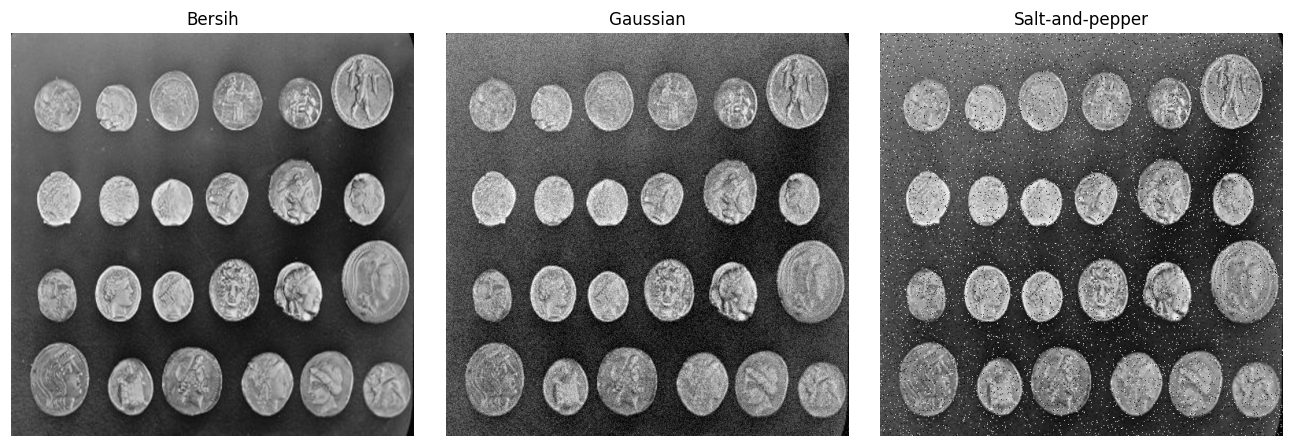

In [26]:
# Gunakan citra latihan yang sama untuk kedua jenis derau.
latihan_gaussian = tambah_derau_gaussian(latihan_bersih, sigma=18, seed=3026)
latihan_sp = tambah_salt_pepper(latihan_bersih, amount=0.05, seed=3027)
bandingkan([latihan_bersih, latihan_gaussian, latihan_sp],
           ["Bersih", "Gaussian", "Salt-and-pepper"], figsize=(12, 4))

### Prediksi mahasiswa: isi sebelum menjalankan empat filter

- Derau Gaussian: saya memprediksi filter `Gaussian` karena filter ini dirancang khusus untuk derau Gaussian dengan pembobotan piksel di sekitarnya yang sesuai dengan distribusi normal derau tersebut, sehingga diharapkan dapat mengurangi derau tanpa terlalu banyak mengaburkan detail koin.
- *Salt-and-pepper*: saya memprediksi filter `Median` karena derau *salt-and-pepper* terdiri dari piksel-piksel ekstrem, dan filter median sangat efektif dalam menghilangkan pencilan ini dengan menggantinya dengan nilai tengah dari lingkungannya, yang kurang rentan terhadap nilai ekstrem.

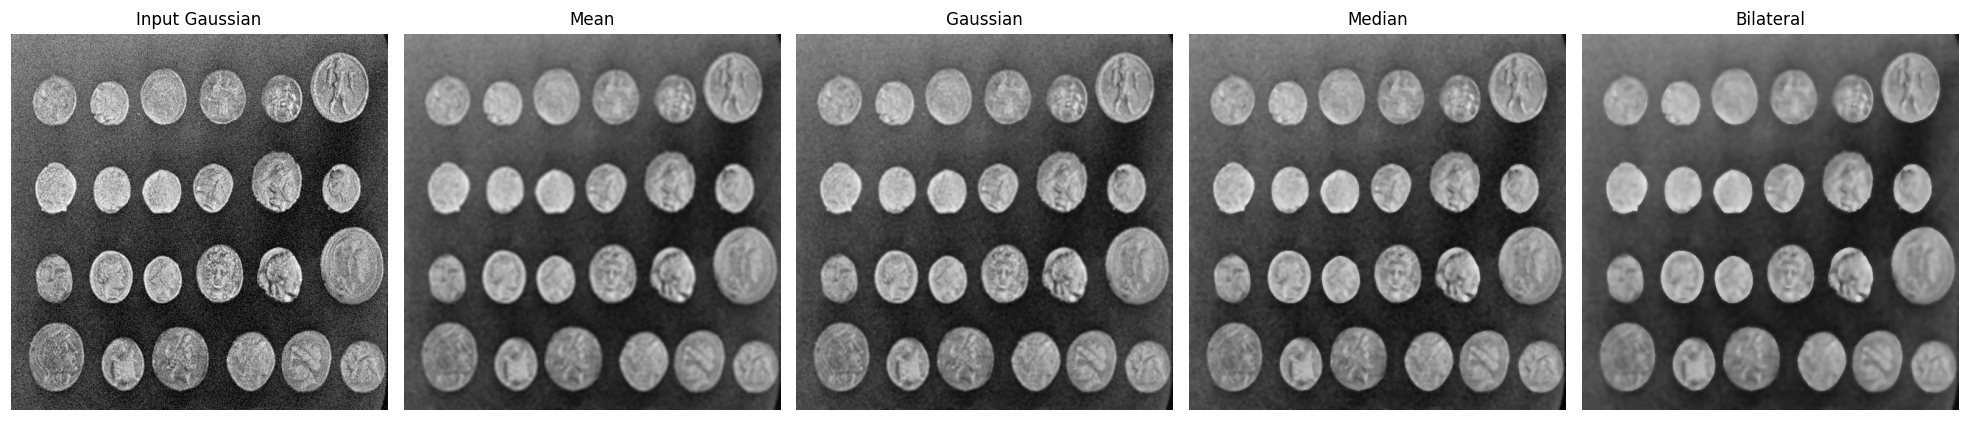

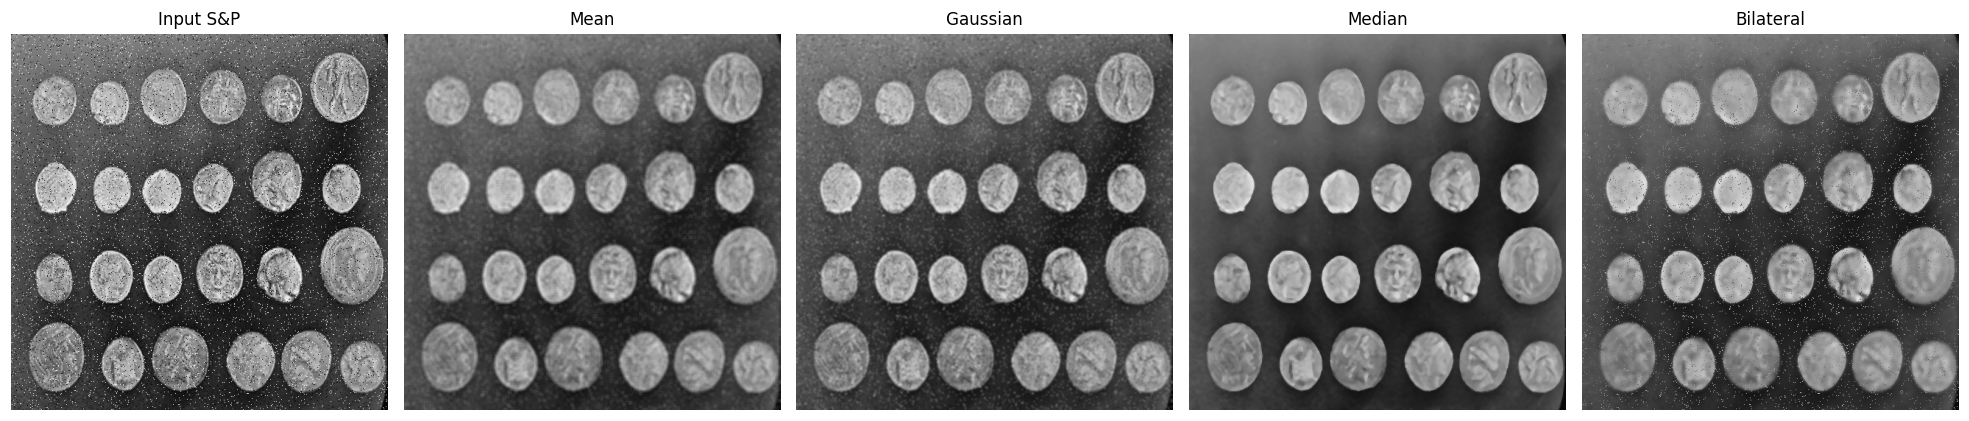

In [27]:
# Ketiga filter pertama memakai ukuran 5 x 5. Bilateral memakai d=9.
# Semua metode menerima input berderau yang sama, tanpa pemrosesan bertingkat.
ukuran_filter = 5
hasil_latihan_gaussian = terapkan_empat_filter(latihan_gaussian, ukuran_filter)
hasil_latihan_sp = terapkan_empat_filter(latihan_sp, ukuran_filter)

bandingkan(
    [latihan_gaussian] + list(hasil_latihan_gaussian.values()),
    ["Input Gaussian"] + list(hasil_latihan_gaussian.keys()),
    figsize=(18, 4),
)

bandingkan(
    [latihan_sp] + list(hasil_latihan_sp.values()),
    ["Input S&P"] + list(hasil_latihan_sp.keys()),
    figsize=(18, 4),
)

### Periksa area koin yang sama

Potongan berikut memuat tepi koin, bagian koin, dan latar. Bandingkan setiap hasil dari area yang identik.

**Jawaban:**

- **Input (Salt-and-pepper):** Terlihat jelas bintik-bintik hitam dan putih yang mengganggu seluruh area, termasuk tepi koin, detail relief koin, dan latar belakang.

- **Mean:** Derau berkurang secara signifikan, namun gambar menjadi sangat buram. Tepi koin menjadi tidak tajam, detail relief koin banyak hilang, dan latar belakang menjadi sangat halus tanpa tekstur. Bintik derau sudah hilang.

- **Gaussian:** Mirip dengan Mean, derau berkurang tetapi gambar masih terlihat buram. Tepi koin sedikit lebih jelas daripada Mean, detail relief masih kabur, dan latar belakang juga halus. Bintik derau masih terlihat sisa-sisanya dalam bentuk bintik abu-abu.

- **Median:** Filter ini sangat efektif menghilangkan bintik-bintik *salt-and-pepper* baik di tepi koin, detail koin, maupun latar belakang, membuat gambar terlihat jauh lebih bersih. Tepi koin dan detail relief koin relatif terjaga dengan baik dibandingkan Mean dan Gaussian, meskipun ada sedikit penghalusan.

- **Bilateral:** Filter Bilateral mempertahankan tepi koin dengan sangat baik, menjadikannya paling tajam di antara semua filter. Detail relief koin juga cukup terjaga. Namun, efeknya terhadap derau *salt-and-pepper* tidak seefektif Median; masih terlihat bintik-bintik derau, terutama di area latar belakang yang datar.

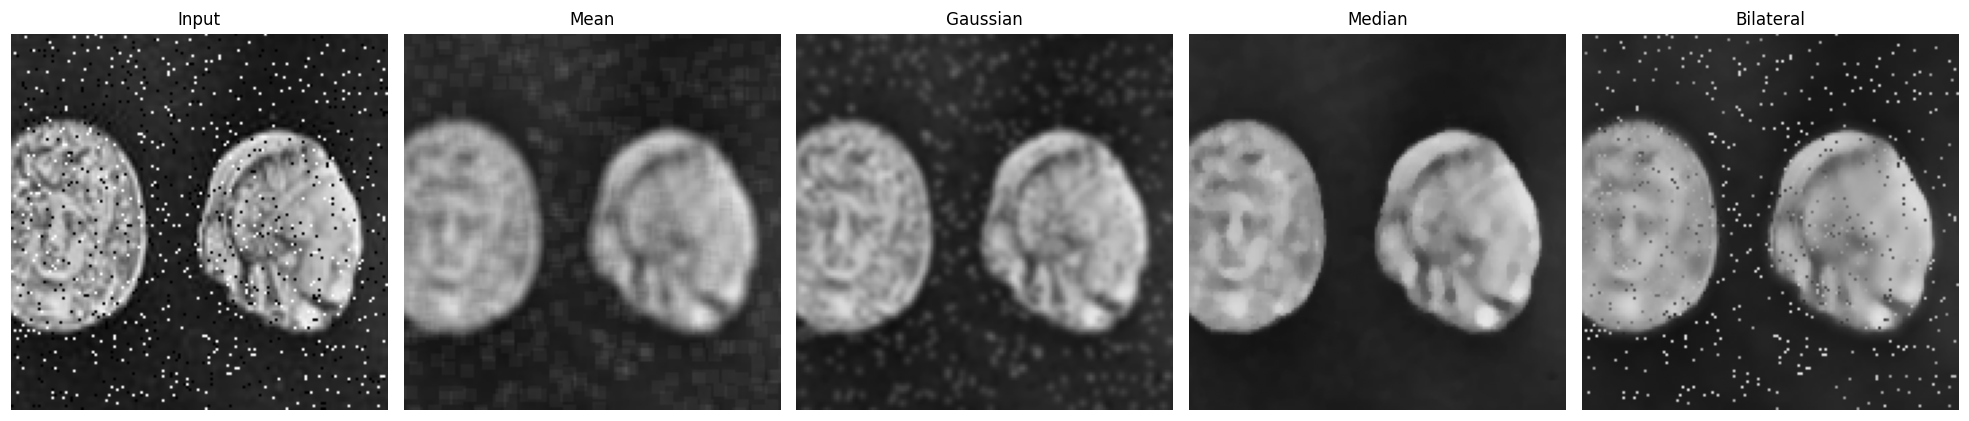

In [28]:
roi_koin = (255, 395, 265, 405)
tampilkan_roi([latihan_sp] + list(hasil_latihan_sp.values()),
             ["Input"] + list(hasil_latihan_sp), roi_koin, figsize=(18, 4))

### Uji ukuran median pada salt-and-pepper

Jalankan ukuran 3, 5, dan 9. Pilih ukuran yang seimbang dengan menyebut bintik yang hilang dan detail koin yang berubah.

**Jawaban:**

Setelah mengamati hasil filter median dengan ukuran 3x3, 5x5, dan 9x9 pada citra koin yang berderau *salt-and-pepper*:

- **Median 3x3:** Filter ini cukup baik dalam mengurangi bintik-bintik derau, namun masih ada beberapa bintik kecil yang terlihat. Detail koin masih sangat terjaga dengan baik.
- **Median 5x5:** Ukuran ini sangat efektif menghilangkan hampir seluruh bintik *salt-and-pepper*. Detail koin sedikit lebih halus dibandingkan 3x3, tetapi masih cukup tajam dan dikenali. Ini menunjukkan keseimbangan yang baik antara penghilangan derau dan pemeliharaan detail.
- **Median 9x9:** Meskipun hampir seluruh derau hilang, filter ini menyebabkan efek penghalusan yang signifikan pada citra. Detail-detail halus pada koin dan tepinya menjadi sangat buram dan sulit dikenali.

Berdasarkan pengamatan ini, ukuran **Median 5x5** adalah pilihan yang paling seimbang. Ia berhasil menghilangkan bintik-bintik *salt-and-pepper* secara efektif tanpa menyebabkan perubahan detail koin yang terlalu drastis, sehingga menghasilkan citra yang bersih namun tetap informatif.

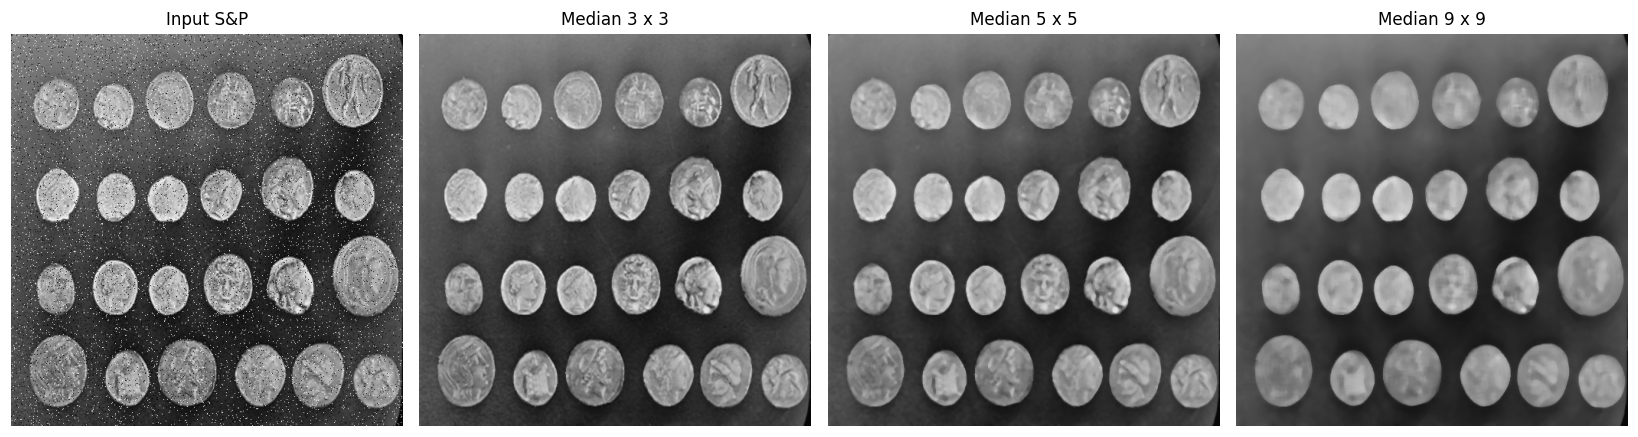

In [29]:
# Ulangi eksperimen ukuran median pada salt-and-pepper.
ukuran_median = [3, 5, 9]
hasil_median_ukuran = [cv2.medianBlur(latihan_sp, k) for k in ukuran_median]
bandingkan(
    [latihan_sp] + hasil_median_ukuran,
    ["Input S&P"] + [f"Median {k} x {k}" for k in ukuran_median],
    figsize=(15, 4),
)

### Tabel pengamatan dan pilihan visual sementara

| Derau | Filter | Derau tersisa | Kondisi tepi | Kondisi tekstur | Keputusan |
|---|---|---|---|---|---|
| Gaussian | Mean | Cukup banyak, gambar blur | Sangat buram | Sangat buram | Kurang baik |
| Gaussian | Gaussian | Sedikit, lebih halus dari Mean | Agak buram, detail koin terjaga | Agak buram | Baik |
| Gaussian | Median | Sedikit, derau berubah bentuk | Cukup tajam, detail koin terjaga | Cukup baik | Baik |
| Gaussian | Bilateral | Sangat sedikit, paling halus | Paling tajam, detail koin sangat baik | Paling baik | Sangat baik |
| Salt-and-pepper | Mean | Hampir hilang, gambar buram | Sangat buram | Sangat buram | Kurang baik |
| Salt-and-pepper | Gaussian | Cukup banyak, bintik masih terlihat | Buram | Buram | Kurang baik |
| Salt-and-pepper | Median | Hampir hilang, paling bersih | Cukup tajam, detail koin terjaga | Cukup baik | Sangat baik |
| Salt-and-pepper | Bilateral | Cukup banyak, bintik masih terlihat | Paling tajam, detail koin baik | Paling baik | Kurang efektif untuk S&P |

**Pilihan sebelum membaca metrik:** Gaussian `Bilateral`; *salt-and-pepper* `Median`. Bukti visual saya terlihat pada area `koin dan latar belakang di sekitarnya`.

## 9. MSE dan PSNR pada citra latihan

Bandingkan nilai dengan pilihan visual sementara. MSE lebih kecil dan PSNR lebih besar menunjukkan galat piksel yang lebih kecil terhadap citra bersih. Jelaskan bila angka dan kesan visual Anda berbeda.

In [30]:
# Baca angka setelah menulis pilihan berdasarkan tampilan citra.
print("Gaussian")
tabel_metrik(latihan_bersih, latihan_gaussian, hasil_latihan_gaussian)
print("\nSalt-and-pepper")
tabel_metrik(latihan_bersih, latihan_sp, hasil_latihan_sp)

Gaussian
Hasil            |       MSE | PSNR (dB)
------------------------------------------
Input berderau   |    321.48 |     23.06
Mean             |    140.36 |     26.66
Gaussian         |     85.15 |     28.83
Median           |    109.44 |     27.74
Bilateral        |    105.31 |     27.91

Salt-and-pepper
Hasil            |       MSE | PSNR (dB)
------------------------------------------
Input berderau   |    995.40 |     18.15
Mean             |    183.19 |     25.50
Gaussian         |    142.28 |     26.60
Median           |     81.43 |     29.02
Bilateral        |    361.04 |     22.56


## 10. Kesimpulan dan pengumpulan

**Kesimpulan 3-5 kalimat:**

Untuk derau **Gaussian**, saya memilih filter **Gaussian** dengan parameter `ksize=5` (dan `sigmaX=1.2, sigmaY=1.2`) karena pada area gambar terlihat derau berkurang signifikan tanpa terlalu banyak mengaburkan detail, terutama dibandingkan dengan filter Mean. MSE hasilnya adalah **85.15** dan PSNR adalah **28.83 dB** (pada citra latihan), yang merupakan yang **terbaik** (tertinggi PSNR dan terendah MSE) untuk derau Gaussian di antara filter yang diuji. Efek samping yang masih terlihat ialah sedikit kehilangan ketajaman pada tepi halus.

Untuk derau ***salt-and-pepper***, saya memilih filter **Median** dengan parameter `ksize=5` karena filter ini secara efektif menghilangkan bintik-bintik derau hitam dan putih tanpa mengganggu struktur lokal. MSE hasilnya adalah **81.43** dan PSNR adalah **29.02 dB** (pada citra latihan), yang merupakan yang terbaik secara keseluruhan untuk jenis derau ini. Efek samping yang masih terlihat ialah sedikit penghalusan pada detail yang sangat halus.

Kumpulkan notebook yang sudah dijalankan. Pastikan prediksi, dua perbandingan empat filter, ROI koin, uji median 3/5/9, tabel delapan baris, metrik, dan kesimpulan sudah terlihat.

**Opsional setelah selesai:** coba citra pribadi. Tanpa citra bersih asli, MSE/PSNR tidak dapat dihitung dengan cara yang sama.